# Dunnhumby The Complete Journey – Retail Customer Analysis

**Data:** [Kaggle – dunnhumby The Complete Journey](https://www.kaggle.com/datasets/frtgnn/dunnhumby-the-complete-journey) (original source: [dunnhumby.com/sourcefiles](https://dunnhumby.com/sourcefiles)).
Grocery purchases of about 2,500 households over **2 years** (102 weeks).

**Main question:** Which customers spend how much, and on what?

1. Overview
2. What time of day do people shop?
3. Top departments and brand type
4. Customer concentration (Pareto)
5. Spending by demographics
6. Coupon use and spending
7. Summary
8. Example: RFM customer segmentation
9. Example: Who is at risk? (propensity model)
10. What we could work on next

## 0. Loading the data
The CSV files downloaded from Kaggle (transaction_data.csv, product.csv, hh_demographic.csv) should be in the same place as this notebook.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

transactions = pd.read_csv("transaction_data.csv")
products = pd.read_csv("product.csv")
demographics = pd.read_csv("hh_demographic.csv")

print("transactions:", transactions.shape)
print("products:", products.shape)
print("demographics:", demographics.shape)
transactions.head()

transactions: (2595732, 12)
products: (92353, 7)
demographics: (801, 8)


,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC
0,2375,26984851472,1,1004906,1,1.39,364,-0.60,1631,1,0.0,0.0
1,2375,26984851472,1,1033142,1,0.82,364,0.00,1631,1,0.0,0.0
2,2375,26984851472,1,1036325,1,0.99,364,-0.30,1631,1,0.0,0.0
3,2375,26984851472,1,1082185,1,1.21,364,0.00,1631,1,0.0,0.0
4,2375,26984851472,1,8160430,1,1.50,364,-0.39,1631,1,0.0,0.0


In [2]:
# Chart settings
BLUE = "#2a78d6"
GRAY = "#8a8984"
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#ecebe8"
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["axes.titleweight"] = "bold"

## 1. Overview

In [3]:
# Total value of each basket (shopping trip)
baskets = transactions.groupby("BASKET_ID")["SALES_VALUE"].sum()

# Total spend and number of baskets per household
households = transactions.groupby("household_key").agg(
    spend=("SALES_VALUE", "sum"),
    baskets=("BASKET_ID", "nunique"))

print("Households:", transactions["household_key"].nunique())
print("Stores:", transactions["STORE_ID"].nunique())
print(f"Distinct products: {transactions['PRODUCT_ID'].nunique():,}")
print(f"Baskets: {len(baskets):,}")
print(f"Total sales: ${transactions['SALES_VALUE'].sum():,.0f}")
print(f"Mean basket value: ${baskets.mean():.2f}")
print(f"Median basket value: ${baskets.median():.2f}")
print(f"2-year spend per household (median): ${households['spend'].median():,.0f}")
print(f"Baskets per household (median): {households['baskets'].median():.0f}")

Households: 2500
Stores: 582
Distinct products: 92,339
Baskets: 276,484
Total sales: $8,057,463
Mean basket value: $29.14
Median basket value: $17.07
2-year spend per household (median): $2,158
Baskets per household (median): 79


## 2. What time of day do people shop?

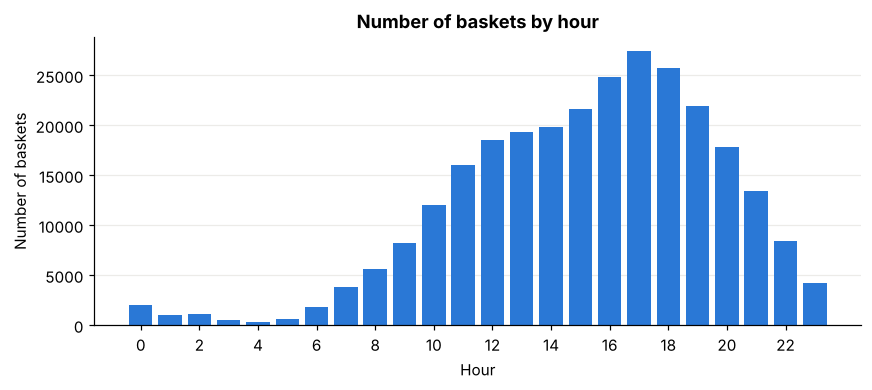

Busiest hour: 17:00
Share of baskets between 16:00 and 20:00: 36%


In [4]:
# TRANS_TIME stores the time as e.g. 1631 (16:31). The first two digits are the hour.
basket_time = transactions.groupby("BASKET_ID")["TRANS_TIME"].first()
hour = basket_time // 100
hour_counts = hour.value_counts().sort_index()

plt.figure(figsize=(9, 3.4))
plt.bar(hour_counts.index, hour_counts.values, color=BLUE, width=0.8)
plt.title("Number of baskets by hour")
plt.xlabel("Hour")
plt.ylabel("Number of baskets")
plt.xticks(range(0, 24, 2))
plt.grid(axis="x", visible=False)
plt.show()

print(f"Busiest hour: {hour_counts.idxmax()}:00")
print(f"Share of baskets between 16:00 and 20:00: {hour_counts.loc[16:19].sum() / hour_counts.sum() * 100:.0f}%")

## 3. Top departments and brand type

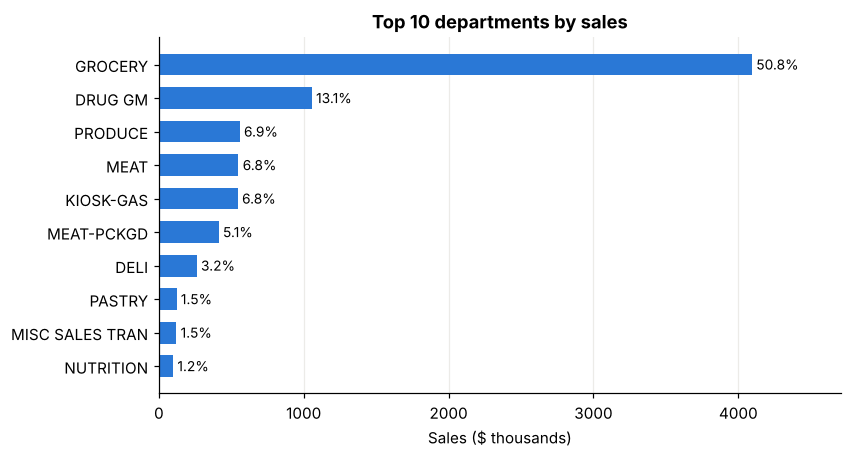

GROCERY share of total sales: 51%


In [5]:
data = transactions.merge(products, on="PRODUCT_ID", how="left")

dept = data.groupby("DEPARTMENT")["SALES_VALUE"].sum().sort_values(ascending=False)
top10 = dept.head(10).sort_values()
share = top10 / dept.sum() * 100

plt.figure(figsize=(8, 4.2))
plt.barh(top10.index, top10.values / 1000, color=BLUE, height=0.65)
for i in range(len(top10)):
    plt.text(top10.values[i] / 1000 + 30, i, f"{share.values[i]:.1f}%", va="center", fontsize=9)
plt.title("Top 10 departments by sales")
plt.xlabel("Sales ($ thousands)")
plt.xlim(0, top10.max() / 1000 * 1.15)
plt.grid(axis="y", visible=False)
plt.show()

print(f"GROCERY share of total sales: {dept['GROCERY'] / dept.sum() * 100:.0f}%")

In [6]:
brand = data.groupby("BRAND")["SALES_VALUE"].sum()
print("Share of sales by brand type (%):")
print((brand / brand.sum() * 100).round(1).to_string())

Share of sales by brand type (%):
BRAND
National    72.2
Private     27.8


## 4. Customer concentration: how much of sales comes from the best customers?

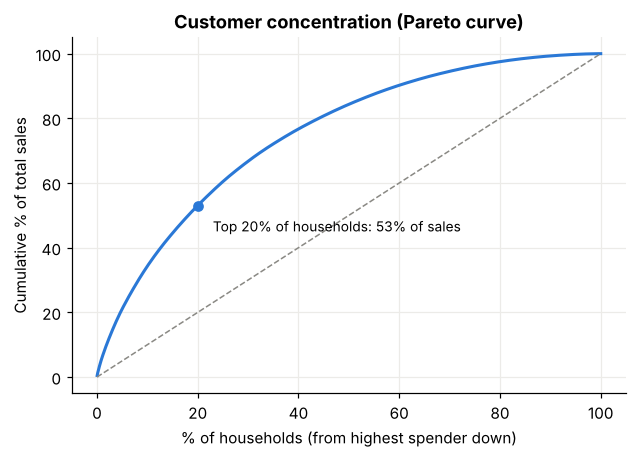

Share of sales from the top 20% of households: 53%
Share of sales from the bottom 50% of households: 16%


In [7]:
spend_sorted = households["spend"].sort_values(ascending=False)
cum_share = spend_sorted.cumsum() / spend_sorted.sum() * 100
pct_households = np.arange(1, len(spend_sorted) + 1) / len(spend_sorted) * 100

top20 = cum_share.iloc[int(len(spend_sorted) * 0.2) - 1]
bottom50 = 100 - cum_share.iloc[int(len(spend_sorted) * 0.5) - 1]

plt.figure(figsize=(6.5, 4.2))
plt.plot(pct_households, cum_share.values, color=BLUE, linewidth=2)
plt.plot([0, 100], [0, 100], color=GRAY, linestyle="--", linewidth=1)
plt.scatter([20], [top20], color=BLUE, zorder=3)
plt.text(23, top20 - 8, f"Top 20% of households: {top20:.0f}% of sales", fontsize=9)
plt.title("Customer concentration (Pareto curve)")
plt.xlabel("% of households (from highest spender down)")
plt.ylabel("Cumulative % of total sales")
plt.show()

print(f"Share of sales from the top 20% of households: {top20:.0f}%")
print(f"Share of sales from the bottom 50% of households: {bottom50:.0f}%")

## 5. Spending by demographics
Note: Demographic data is available for **only 801 of the 2,500 households**. Each chart shows the number of households (n) per group.

In [8]:
hh_demo = households.reset_index().merge(demographics, on="household_key")

print("Households with demographics:", len(hh_demo))
print(f"Median spend - households with demographics: ${hh_demo['spend'].median():,.0f}")
print(f"Median spend - all households: ${households['spend'].median():,.0f}")
print("Households with demographics shop more than average. Be careful when generalizing.")

# High-income groups have very few households, so we merge income bands
income_groups = {
    "Under 15K": "<25K", "15-24K": "<25K",
    "25-34K": "25-49K", "35-49K": "25-49K",
    "50-74K": "50-74K", "75-99K": "75-99K",
    "100-124K": "100-149K", "125-149K": "100-149K",
    "150-174K": "150K+", "175-199K": "150K+", "200-249K": "150K+", "250K+": "150K+",
}
hh_demo["income_group"] = hh_demo["INCOME_DESC"].map(income_groups)

Households with demographics: 801
Median spend - households with demographics: $4,676
Median spend - all households: $2,158
Households with demographics shop more than average. Be careful when generalizing.


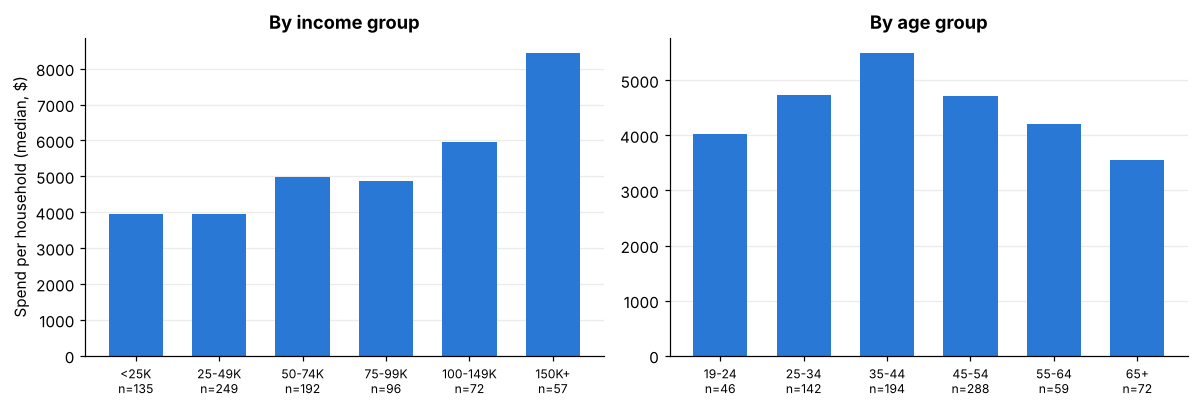

In [9]:
income_order = ["<25K", "25-49K", "50-74K", "75-99K", "100-149K", "150K+"]
age_order = ["19-24", "25-34", "35-44", "45-54", "55-64", "65+"]

by_income = hh_demo.groupby("income_group")["spend"].agg(["median", "count"]).loc[income_order]
by_age = hh_demo.groupby("AGE_DESC")["spend"].agg(["median", "count"]).loc[age_order]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

labels = [f"{g}\nn={n}" for g, n in zip(by_income.index, by_income["count"])]
axes[0].bar(labels, by_income["median"], color=BLUE, width=0.65)
axes[0].set_title("By income group")
axes[0].set_ylabel("Spend per household (median, $)")

labels = [f"{g}\nn={n}" for g, n in zip(by_age.index, by_age["count"])]
axes[1].bar(labels, by_age["median"], color=BLUE, width=0.65)
axes[1].set_title("By age group")

for ax in axes:
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", labelsize=8)
plt.tight_layout()
plt.show()

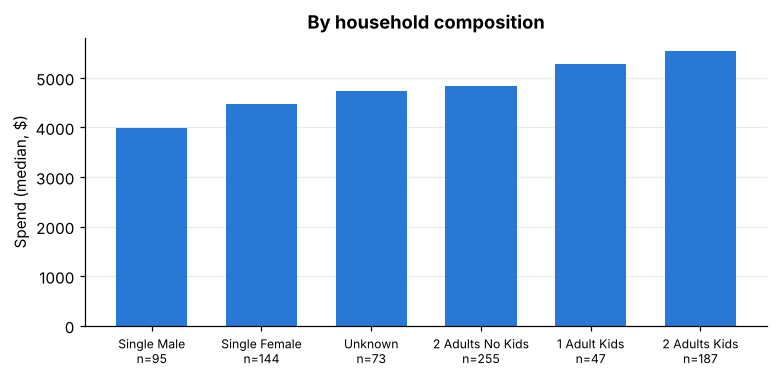

,median,count
HH_COMP_DESC,,
Single Male,3984.0,95
Single Female,4482.0,144
Unknown,4725.0,73
2 Adults No Kids,4828.0,255
1 Adult Kids,5274.0,47
2 Adults Kids,5532.0,187


In [10]:
by_comp = hh_demo.groupby("HH_COMP_DESC")["spend"].agg(["median", "count"]).sort_values("median")

plt.figure(figsize=(8, 3.4))
labels = [f"{g}\nn={n}" for g, n in zip(by_comp.index, by_comp["count"])]
plt.bar(labels, by_comp["median"], color=BLUE, width=0.65)
plt.title("By household composition")
plt.ylabel("Spend (median, $)")
plt.xticks(fontsize=8)
plt.grid(axis="x", visible=False)
plt.show()

by_comp.round(0)

## 6. Coupon use and spending

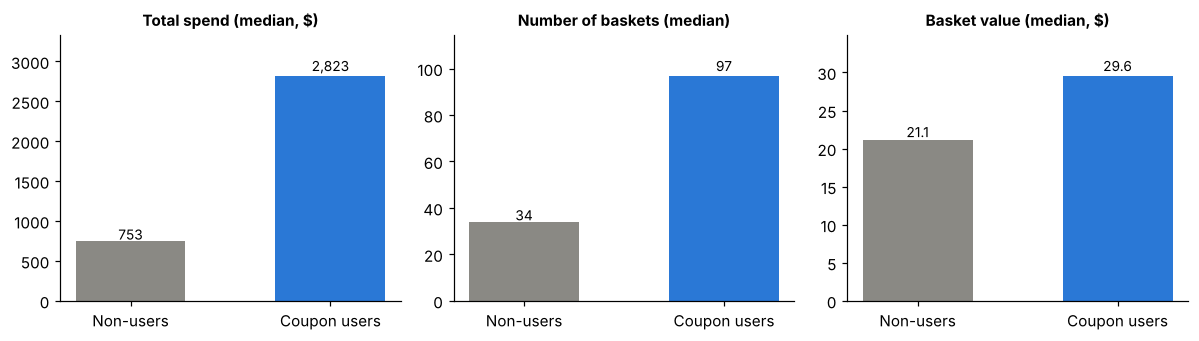

Coupon-using households: 1858
Coupon users spend 3.8x more (median).
Caution: this is a correlation. Households that shop more also have more chances to use coupons.


,households,median_spend,median_baskets,median_basket_value
Non-users,642,752.6,34.0,21.1
Coupon users,1858,2823.4,97.0,29.6


In [11]:
# In this data, discounts are stored as negative numbers
coupon_households = transactions.loc[transactions["COUPON_DISC"] < 0, "household_key"].unique()
households["coupon_user"] = households.index.isin(coupon_households)
households["avg_basket"] = households["spend"] / households["baskets"]

comparison = households.groupby("coupon_user").agg(
    households=("spend", "count"),
    median_spend=("spend", "median"),
    median_baskets=("baskets", "median"),
    median_basket_value=("avg_basket", "median"))
comparison.index = ["Non-users", "Coupon users"]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
columns = ["median_spend", "median_baskets", "median_basket_value"]
titles = ["Total spend (median, $)", "Number of baskets (median)", "Basket value (median, $)"]
for ax, col, title in zip(axes, columns, titles):
    ax.bar(comparison.index, comparison[col], color=[GRAY, BLUE], width=0.55)
    for i, v in enumerate(comparison[col]):
        ax.text(i, v * 1.02, f"{v:.1f}" if col == "median_basket_value" else f"{v:,.0f}", ha="center", fontsize=9)
    ax.set_title(title, fontsize=10)
    ax.set_ylim(0, comparison[col].max() * 1.18)
    ax.grid(False)
plt.tight_layout()
plt.show()

ratio = comparison.loc["Coupon users", "median_spend"] / comparison.loc["Non-users", "median_spend"]
print("Coupon-using households:", comparison.loc["Coupon users", "households"])
print(f"Coupon users spend {ratio:.1f}x more (median).")
print("Caution: this is a correlation. Households that shop more also have more chances to use coupons.")
comparison.round(1)

## 7. Summary

**Key findings** (numbers come from the cells above):
- Shopping peaks in the afternoon and early evening. The busiest hour is 17:00.
- GROCERY alone makes up half of sales (51%). About 28% of sales come from private-label (store brand) products.
- Sales are concentrated in a small group of households: the top 20% account for 53% of sales, the bottom 50% for only 16%.
- Spending rises with income. By age, it peaks in the 35–44 group. Households with kids spend more.
- Coupon users spend about 4 times more, but this does not show causality.

**Limitation:** Demographic data covers only 801 households, and these households shop more than average.

## 8. Example: RFM customer segmentation

Here we try the first idea from our team meeting: group customers by their spending habits, then look at who they are.

For each household we calculate three RFM values:
- **Recency:** how many days since their last purchase (lower is better)
- **Frequency:** how many shopping trips (baskets) they made
- **Monetary:** how much they spent in total

Then we use **K-means** to put similar households into groups.

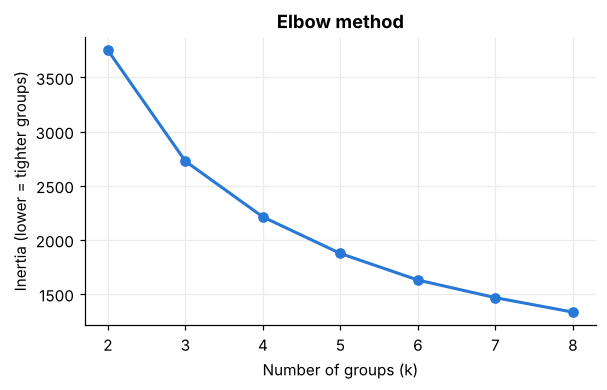

There is no sharp elbow, but the drop slows down after k = 4, and 4 groups are easy to explain, so we use 4.


In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# RFM values for each household
last_day = transactions["DAY"].max() + 1
rfm = transactions.groupby("household_key").agg(
    recency=("DAY", lambda days: last_day - days.max()),
    frequency=("BASKET_ID", "nunique"),
    monetary=("SALES_VALUE", "sum"))

# The values are very skewed, so we take the log and put them on the same scale
scaler_rfm = StandardScaler()
rfm_scaled = scaler_rfm.fit_transform(np.log1p(rfm[["recency", "frequency", "monetary"]]))

# Elbow method: try different numbers of groups (k)
k_values = range(2, 9)
inertia = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(rfm_scaled).inertia_ for k in k_values]

plt.figure(figsize=(6, 3.4))
plt.plot(list(k_values), inertia, color=BLUE, marker="o", linewidth=2)
plt.title("Elbow method")
plt.xlabel("Number of groups (k)")
plt.ylabel("Inertia (lower = tighter groups)")
plt.show()
print("There is no sharp elbow, but the drop slows down after k = 4, and 4 groups are easy to explain, so we use 4.")

In [13]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
rfm["cluster"] = kmeans.fit_predict(rfm_scaled)

# Profile of each group (medians)
profile = rfm.groupby("cluster").agg(
    households=("monetary", "count"),
    recency=("recency", "median"),
    frequency=("frequency", "median"),
    monetary=("monetary", "median"),
    total_sales=("monetary", "sum"))

# Give each group a name based on its profile
best = profile["frequency"].idxmax()
lapsing = profile["recency"].idxmax()
others = profile.drop([best, lapsing]).sort_values("recency")
names = {best: "Best customers",
         others.index[0]: "Active regulars",
         others.index[1]: "Slipping away",
         lapsing: "Lapsing, low value"}
rfm["segment"] = rfm["cluster"].map(names)
profile.index = profile.index.map(names)

segment_order = ["Best customers", "Active regulars", "Slipping away", "Lapsing, low value"]
profile = profile.loc[segment_order]
profile["% of households"] = (profile["households"] / profile["households"].sum() * 100).round(1)
profile["% of sales"] = (profile["total_sales"] / profile["total_sales"].sum() * 100).round(1)
profile[["households", "recency", "frequency", "monetary", "% of households", "% of sales"]].round(0)

,households,recency,frequency,monetary,% of households,% of sales
cluster,,,,,,
Best customers,913,3.0,166.0,5255.0,36.0,70.0
Active regulars,647,4.0,57.0,1462.0,26.0,13.0
Slipping away,576,22.0,58.0,1748.0,23.0,15.0
"Lapsing, low value",364,55.0,15.0,313.0,15.0,2.0


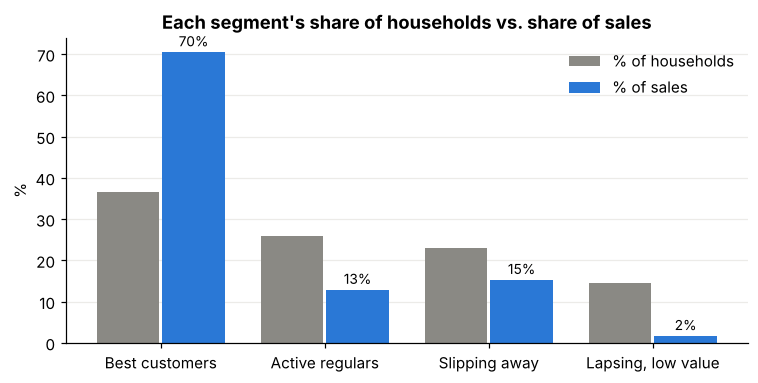

In [14]:
x = np.arange(len(profile))
plt.figure(figsize=(8, 3.6))
plt.bar(x - 0.2, profile["% of households"], width=0.38, color=GRAY, label="% of households")
plt.bar(x + 0.2, profile["% of sales"], width=0.38, color=BLUE, label="% of sales")
for i in range(len(profile)):
    plt.text(x[i] + 0.2, profile["% of sales"].iloc[i] + 1.5, f"{profile['% of sales'].iloc[i]:.0f}%", ha="center", fontsize=9)
plt.xticks(x, profile.index)
plt.ylabel("%")
plt.title("Each segment's share of households vs. share of sales")
plt.legend(frameon=False)
plt.grid(axis="x", visible=False)
plt.show()

### Adding demographics to the segments

Next, we combine the segments with the demographic data (only 801 households have it). This shows the "who" behind each spending pattern.

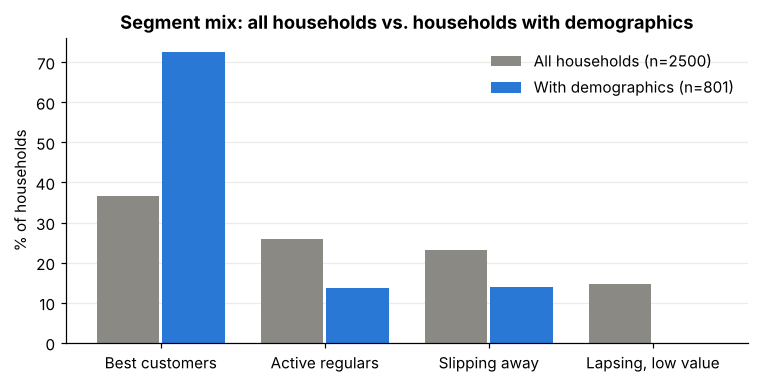

Households with demographics are mostly 'Best customers', so demographic results
describe the store's most loyal shoppers, not all customers.


,% Best customers,Households
income_group,,
<25K,67.0,135
25-49K,72.0,249
50-74K,76.0,192
75-99K,66.0,96
100-149K,75.0,72
150K+,84.0,57


In [15]:
seg_demo = rfm.reset_index().merge(demographics, on="household_key")
seg_demo["income_group"] = seg_demo["INCOME_DESC"].map(income_groups)

# Are households with demographics similar to all households?
mix_all = rfm["segment"].value_counts(normalize=True).reindex(segment_order, fill_value=0) * 100
mix_demo = seg_demo["segment"].value_counts(normalize=True).reindex(segment_order, fill_value=0) * 100

x = np.arange(len(segment_order))
plt.figure(figsize=(8, 3.6))
plt.bar(x - 0.2, mix_all, width=0.38, color=GRAY, label=f"All households (n={len(rfm)})")
plt.bar(x + 0.2, mix_demo, width=0.38, color=BLUE, label=f"With demographics (n={len(seg_demo)})")
plt.xticks(x, segment_order)
plt.ylabel("% of households")
plt.title("Segment mix: all households vs. households with demographics")
plt.legend(frameon=False)
plt.grid(axis="x", visible=False)
plt.show()

print("Households with demographics are mostly 'Best customers', so demographic results")
print("describe the store's most loyal shoppers, not all customers.")

# Share of "Best customers" in each income group (households with demographics only)
best_by_income = (seg_demo.assign(best=seg_demo["segment"] == "Best customers")
                  .groupby("income_group")["best"].agg(["mean", "count"]).loc[income_order])
best_by_income.columns = ["% Best customers", "Households"]
best_by_income["% Best customers"] = (best_by_income["% Best customers"] * 100).round(0)
best_by_income

## 9. Example: Who is at risk? (propensity model)

This is the second idea from our meeting: a supervised model that gives each customer a **probability score**.

In this dataset almost every household keeps shopping at least a little, so "did they come back at all?" is not very useful (about 93% do). Instead we ask a more practical question:

**Will a customer's spending drop by more than half in the next 3 months?** We call these customers "at risk".

To avoid using the future to predict the future, we split the timeline:
- **Feature window:** everything up to day 620 → used to describe each customer
- **Target window:** days 621–711 (about 13 weeks) → used only to check what actually happened

In [16]:
cutoff = 620
past = transactions[transactions["DAY"] <= cutoff]
future = transactions[transactions["DAY"] > cutoff]

# Features: only from the past
features = past.groupby("household_key").agg(
    recency=("DAY", lambda days: cutoff - days.max()),
    frequency=("BASKET_ID", "nunique"),
    monetary=("SALES_VALUE", "sum"),
    products=("PRODUCT_ID", "nunique"),
    coupon_uses=("COUPON_DISC", lambda d: (d < 0).sum()))
features["avg_basket"] = features["monetary"] / features["frequency"]

# Spending in the last 13 weeks and the 13 weeks before that
last_13w = past[past["DAY"] > cutoff - 91].groupby("household_key")["SALES_VALUE"].sum()
prev_13w = past[(past["DAY"] > cutoff - 182) & (past["DAY"] <= cutoff - 91)].groupby("household_key")["SALES_VALUE"].sum()
features["spend_last_13w"] = last_13w
features["spend_prev_13w"] = prev_13w
features = features.fillna(0)
features["trend"] = (features["spend_last_13w"] + 1) / (features["spend_prev_13w"] + 1)

# Target: spending in the next 13 weeks is less than half of the last 13 weeks
features["spend_next_13w"] = future.groupby("household_key")["SALES_VALUE"].sum()
features = features.fillna(0)
features = features[features["spend_last_13w"] > 0]   # only customers who were active recently
features["at_risk"] = (features["spend_next_13w"] < 0.5 * features["spend_last_13w"]).astype(int)

print("Customers in the model:", len(features))
print(f"At-risk customers: {features['at_risk'].mean() * 100:.1f}%")

Customers in the model: 2323
At-risk customers: 16.8%


In [17]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, classification_report

feature_cols = ["recency", "frequency", "monetary", "products", "coupon_uses",
                "avg_basket", "spend_last_13w", "spend_prev_13w", "trend"]
X = np.log1p(features[feature_cols])
y = features["at_risk"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

scaler = StandardScaler().fit(X_train)
logreg = LogisticRegression(max_iter=1000, class_weight="balanced")
logreg.fit(scaler.transform(X_train), y_train)
p_logreg = logreg.predict_proba(scaler.transform(X_test))[:, 1]

forest = RandomForestClassifier(n_estimators=300, max_depth=6, class_weight="balanced", random_state=42)
forest.fit(X_train, y_train)
p_forest = forest.predict_proba(X_test)[:, 1]

print(f"ROC AUC - Logistic regression: {roc_auc_score(y_test, p_logreg):.2f}")
print(f"ROC AUC - Random forest:       {roc_auc_score(y_test, p_forest):.2f}")
print("(0.5 = random guessing, 1.0 = perfect)\n")
print("Logistic regression, threshold 0.5:")
print(classification_report(y_test, (p_logreg > 0.5).astype(int), target_names=["Not at risk", "At risk"]))

ROC AUC - Logistic regression: 0.67
ROC AUC - Random forest:       0.65
(0.5 = random guessing, 1.0 = perfect)

Logistic regression, threshold 0.5:
              precision    recall  f1-score   support

 Not at risk       0.89      0.66      0.76       483
     At risk       0.26      0.60      0.37        98

    accuracy                           0.65       581
   macro avg       0.58      0.63      0.56       581
weighted avg       0.78      0.65      0.69       581



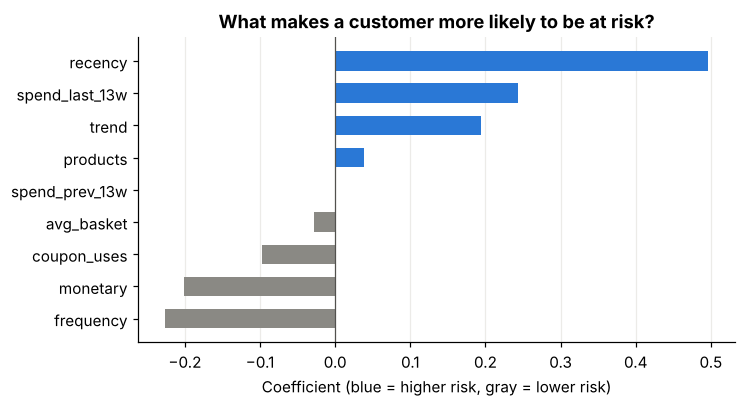

In [18]:
# Which features push the risk up or down? (logistic regression coefficients)
coefs = pd.Series(logreg.coef_[0], index=feature_cols).sort_values()

plt.figure(figsize=(7, 3.6))
plt.barh(coefs.index, coefs.values, color=[GRAY if c < 0 else BLUE for c in coefs.values], height=0.6)
plt.axvline(0, color="#52514e", linewidth=0.8)
plt.title("What makes a customer more likely to be at risk?")
plt.xlabel("Coefficient (blue = higher risk, gray = lower risk)")
plt.grid(axis="y", visible=False)
plt.show()

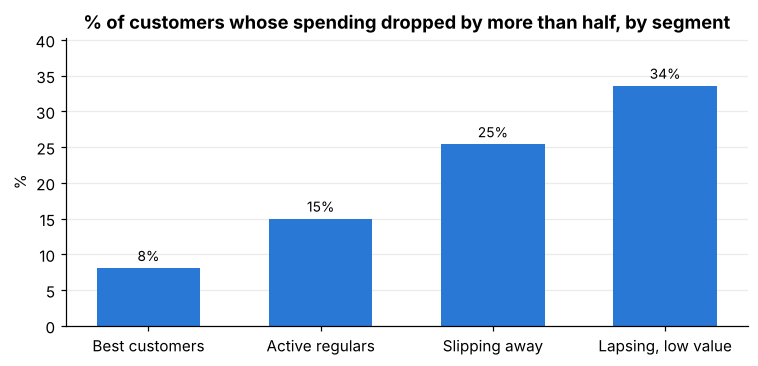

Top 10 customers with the highest risk score:


,segment,recency,frequency,spend_last_13w,trend,risk_score
household_key,,,,,,
1813,"Lapsing, low value",17,3,200.26,201.26,0.91
1342,"Lapsing, low value",66,9,92.57,47.02,0.90
613,"Lapsing, low value",80,6,51.59,52.59,0.90
651,"Lapsing, low value",89,8,72.20,73.20,0.90
872,"Lapsing, low value",50,8,68.70,69.70,0.89
310,"Lapsing, low value",69,5,30.21,31.21,0.89
1059,"Lapsing, low value",65,5,24.92,25.92,0.89
2101,"Lapsing, low value",14,5,189.92,190.92,0.89
1276,"Lapsing, low value",69,17,98.79,99.79,0.88


In [19]:
# Probability score for every customer
features["risk_score"] = logreg.predict_proba(scaler.transform(np.log1p(features[feature_cols])))[:, 1]

# Link with the segments: use the same K-means model on RFM values measured at the cutoff
rfm_cut = features[["recency", "frequency", "monetary"]]
features["segment"] = pd.Series(kmeans.predict(scaler_rfm.transform(np.log1p(rfm_cut))), index=features.index).map(names)

by_segment = features.groupby("segment").agg(
    customers=("at_risk", "count"),
    actual_at_risk=("at_risk", "mean"),
    avg_risk_score=("risk_score", "mean")).loc[segment_order]

plt.figure(figsize=(8, 3.4))
plt.bar(by_segment.index, by_segment["actual_at_risk"] * 100, color=BLUE, width=0.6)
for i, v in enumerate(by_segment["actual_at_risk"] * 100):
    plt.text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=9)
plt.ylim(0, by_segment["actual_at_risk"].max() * 100 * 1.2)
plt.title("% of customers whose spending dropped by more than half, by segment")
plt.ylabel("%")
plt.grid(axis="x", visible=False)
plt.show()

print("Top 10 customers with the highest risk score:")
features.sort_values("risk_score", ascending=False)[["segment", "recency", "frequency", "spend_last_13w", "trend", "risk_score"]].head(10).round(2)

### What we learned from the examples

- **Segmentation:** The "Best customers" group is about a third of households but brings in about 70% of sales. The "Slipping away" and "Lapsing" groups have not shopped for a while and spend much less.
- **Demographics:** Almost all households with demographic data are "Best customers", and none of them are "Lapsing". So the demographic part only tells us about the most loyal shoppers. Within that group, the highest-income households (150K+) are the most likely to be "Best customers".
- **Propensity model:** The model is better than random guessing, but not strong yet (ROC AUC about 0.67). The biggest warning sign is **recency**: the longer since the last visit, the higher the risk. Interestingly, customers whose spending recently went **up** are also more likely to drop, probably because an unusually high period is often followed by a return to normal. Frequent shoppers and coupon users are less likely to be at risk.
- **The two ideas connect:** The share of at-risk customers grows from about 8% in "Best customers" to about 34% in "Lapsing". So segmentation tells us *who* the customers are, and the propensity model tells us *which ones* to focus on.

**Limitations:** Only 801 households have demographics, and they are mostly the best customers. The 50% drop rule and the day-620 cutoff are our own choices, and changing them may change the results. The model only uses purchase behavior, so adding demographics or campaign data could improve it.

## 10. What we could work on next

Sections 8 and 9 are first examples of the ideas from our team meeting (Retail Marketing: customer segmentation, customer retention and value). Possible next steps:

**1. Make the segmentation richer**
Add more behavior features (coupon use, private-label share, favorite departments) and compare K-means with other methods. We could also test other numbers of groups.

**2. Campaign response propensity model**
This dataset also has campaign files (campaign_table, campaign_desc, coupon_redemp). We could predict which households are likely to redeem a coupon from a campaign and give each household a probability score.

**3. Stretch goal: does the campaign actually cause the purchase? (causal ML)**
Some customers buy anyway, with or without a campaign (for example, loyal customers). Methods like S/T/X learners estimate the *extra* effect of the campaign for each customer (CATE). One limitation: campaigns in this dataset were not assigned randomly, so we would need strong assumptions.

**4. Improve the at-risk model**
Try other cutoffs and definitions of "at risk", add demographics or campaign features, and compare more models.

**Not included:** sales forecasting / time series, since the program discourages time series analysis.